# Predicting Building Energy Efficiency — CS316 Project

**Group members:** Sarah AlSahhaf, Nourah AlMuhanna
**Course:** CS316 — Introduction to AI and Data Science
**Instructor:** Dr. Heyfa Ammar

This notebook predicts the **heating load** and **cooling load** of residential buildings
from their design features, using the UCI *Energy Efficiency* dataset. We predict the two
loads with **separate regression models**.

**Pipeline:**
1. Imports
2. Load the dataset (directly from UCI)
3. Inspect the data
4. Data cleaning
5. Memory optimization
6. Outlier check
7. Exploratory Data Analysis (EDA)
8. Features, targets, train/test split
9. Scaling (fit on training only)
10. Feature engineering + PCA
11. Regression models (per target)
12. Evaluation: R², MAE, RMSE
13. Cross-validation
14. Feature importance
15. Summary


## 1. Imports

In [1]:
# Core data libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling and preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Consistent, readable plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

The **Energy Efficiency** dataset from the UCI Machine Learning Repository (ID 242):
**768 rows**, **8 input features**, **2 targets** (heating and cooling load).

We load it directly with `ucimlrepo` so there's nothing to download by hand. If the package
isn't installed (e.g. a fresh Colab), the first line installs it.


In [2]:
# Install the UCI helper package if needed
try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    !pip install ucimlrepo -q
    from ucimlrepo import fetch_ucirepo

# Fetch the Energy Efficiency dataset (UCI id = 242)
energy = fetch_ucirepo(id=242)

# Features (X1..X8) and targets (Y1, Y2), joined into one DataFrame
df = pd.concat([energy.data.features, energy.data.targets], axis=1)

print("Dataset loaded. Shape:", df.shape)

Dataset loaded. Shape: (768, 10)


The original columns are named `X1`–`X8` and `Y1`, `Y2`. The order is fixed, so we rename
them to clear, descriptive names.


In [3]:
df.columns = [
    "relative_compactness",        # X1
    "surface_area",                # X2
    "wall_area",                   # X3
    "roof_area",                   # X4
    "overall_height",              # X5
    "orientation",                 # X6
    "glazing_area",                # X7
    "glazing_area_distribution",   # X8
    "heating_load",                # Y1 (target)
    "cooling_load",                # Y2 (target)
]

df.head()

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## 3. Inspect the Data

Look at the structure, data types, and basic statistics before touching anything.


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   relative_compactness       768 non-null    float64
 1   surface_area               768 non-null    float64
 2   wall_area                  768 non-null    float64
 3   roof_area                  768 non-null    float64
 4   overall_height             768 non-null    float64
 5   orientation                768 non-null    int64  
 6   glazing_area               768 non-null    float64
 7   glazing_area_distribution  768 non-null    int64  
 8   heating_load               768 non-null    float64
 9   cooling_load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [5]:
df.describe()

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307201,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090196,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


## 4. Data Cleaning

Check for **missing values** and **duplicate rows**. The dataset is known to be clean, but
we verify rather than assume.


In [6]:
# Missing values per column
missing = df.isnull().sum()
print("Missing values per column:")
print(missing)
print("\nTotal missing values:", missing.sum())

Missing values per column:
relative_compactness         0
surface_area                 0
wall_area                    0
roof_area                    0
overall_height               0
orientation                  0
glazing_area                 0
glazing_area_distribution    0
heating_load                 0
cooling_load                 0
dtype: int64

Total missing values: 0


In [7]:
# Duplicate rows
num_duplicates = df.duplicated().sum()
print("Number of duplicate rows:", num_duplicates)

# If duplicates existed we would drop them:
# df = df.drop_duplicates().reset_index(drop=True)

Number of duplicate rows: 0


## 5. Memory Optimization

All columns load as 64-bit numbers by default, which is more precision than we need. We
**downcast** them to smaller types and compare memory usage before and after.


In [8]:
# Memory before (KB)
mem_before = df.memory_usage(deep=True).sum() / 1024
print(f"Memory before optimization: {mem_before:.2f} KB")

# Downcast floats and ints to the smallest type that fits
float_cols = df.select_dtypes(include=["float64"]).columns
df[float_cols] = df[float_cols].apply(pd.to_numeric, downcast="float")
int_cols = df.select_dtypes(include=["int64"]).columns
df[int_cols] = df[int_cols].apply(pd.to_numeric, downcast="integer")

# Memory after (KB)
mem_after = df.memory_usage(deep=True).sum() / 1024
print(f"Memory after optimization:  {mem_after:.2f} KB")
print(f"Reduction: {100 * (mem_before - mem_after) / mem_before:.1f}%")

df.dtypes

Memory before optimization: 60.13 KB
Memory after optimization:  25.63 KB
Reduction: 57.4%


,0
relative_compactness,float32
surface_area,float32
wall_area,float32
roof_area,float32
overall_height,float32
orientation,int8
glazing_area,float32
glazing_area_distribution,int8
heating_load,float32
cooling_load,float32


## 6. Outlier Check

We check outliers with boxplots and the **IQR rule** (a value is an outlier if it's below
`Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`).

In this dataset the "outliers" are valid building designs, not errors, so we **report** them
but don't delete them — removing valid data would hurt the model.


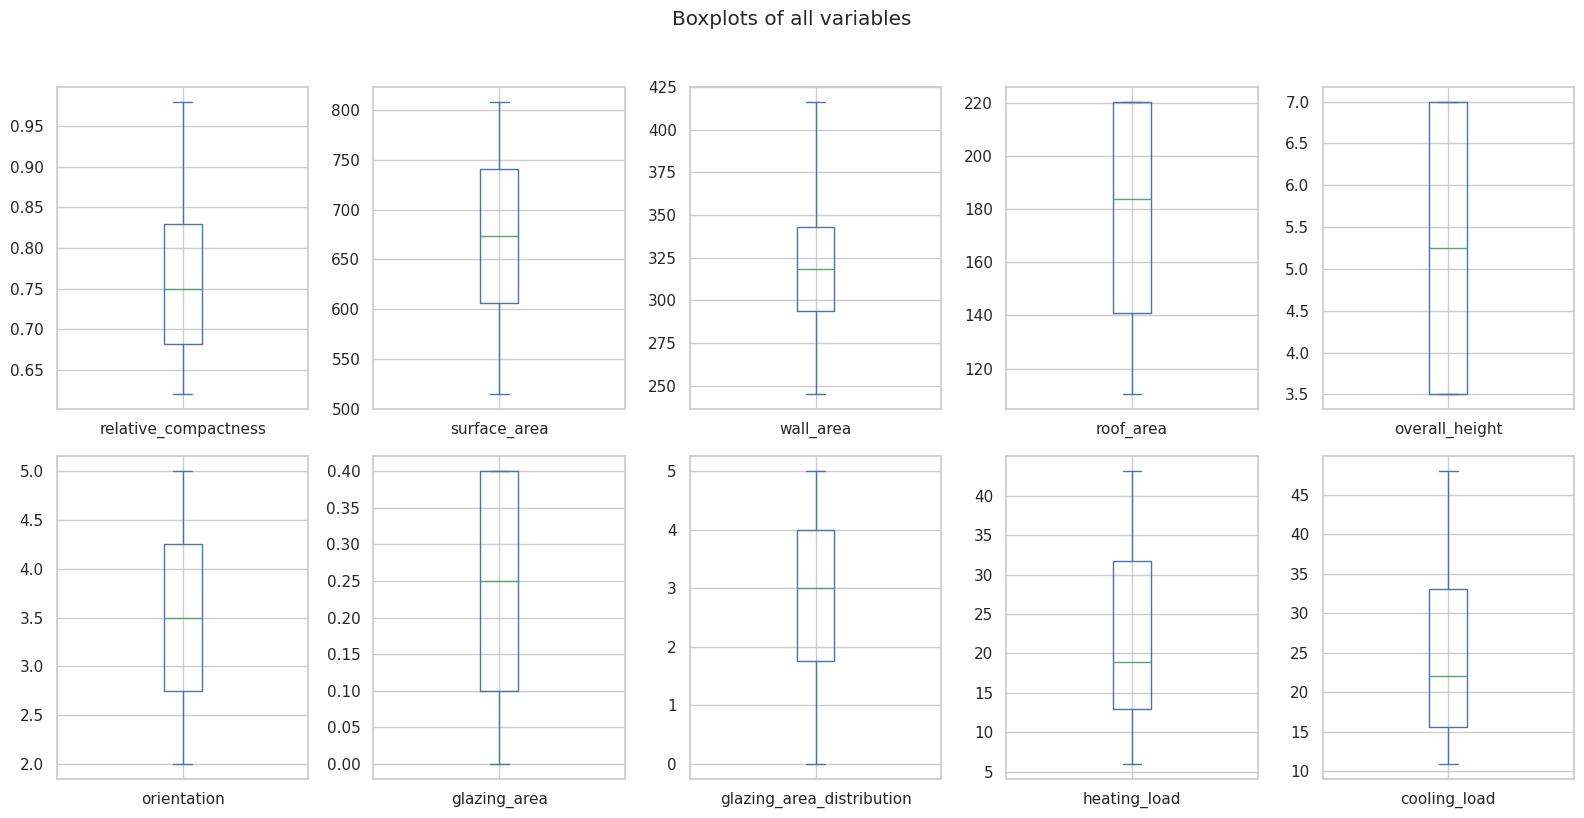

In [9]:
df.plot(kind="box", subplots=True, layout=(2, 5), figsize=(16, 8),
        sharex=False, sharey=False)
plt.suptitle("Boxplots of all variables", y=1.02)
plt.tight_layout()
plt.show()

In [10]:
def count_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    return ((series < lower) | (series > upper)).sum()

print("Number of IQR outliers per column:")
print(df.apply(count_outliers))

Number of IQR outliers per column:
relative_compactness         0
surface_area                 0
wall_area                    0
roof_area                    0
overall_height               0
orientation                  0
glazing_area                 0
glazing_area_distribution    0
heating_load                 0
cooling_load                 0
dtype: int64


## 7. Exploratory Data Analysis (EDA)

Explore relationships to understand **which design features drive energy use**.


### 7.1 Distributions

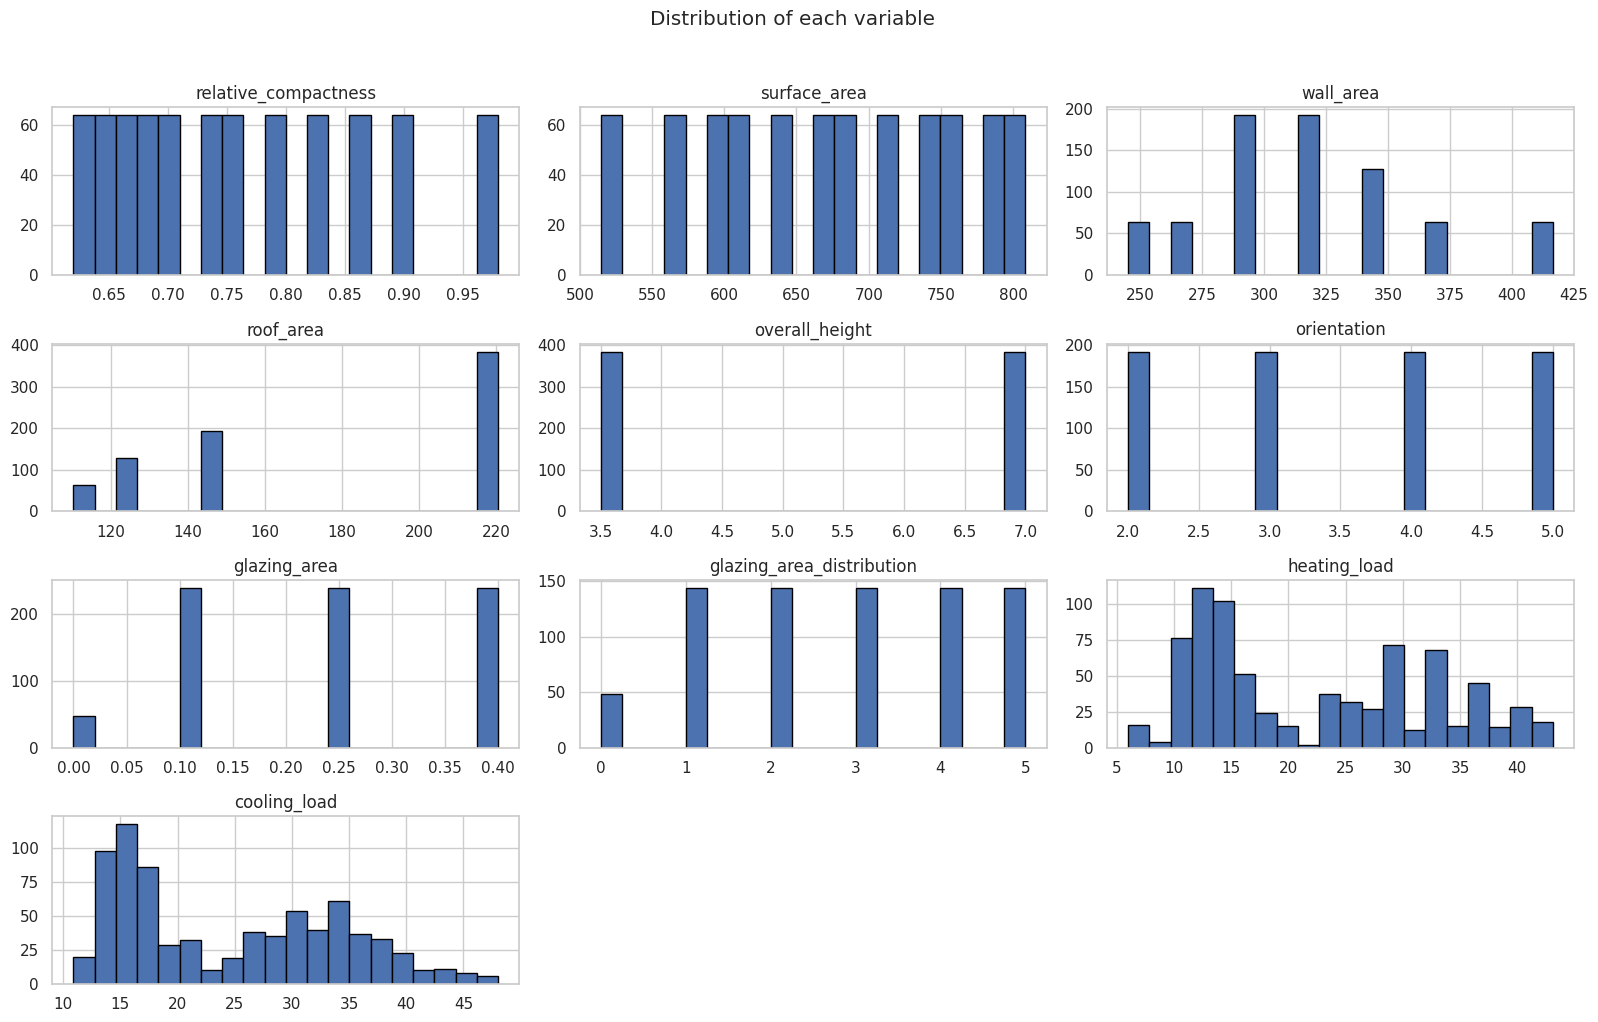

In [11]:
df.hist(bins=20, figsize=(16, 10), edgecolor="black")
plt.suptitle("Distribution of each variable", y=1.02)
plt.tight_layout()
plt.show()

### 7.2 Correlation heatmap

Look especially at the heating and cooling rows to see which features relate to energy use.


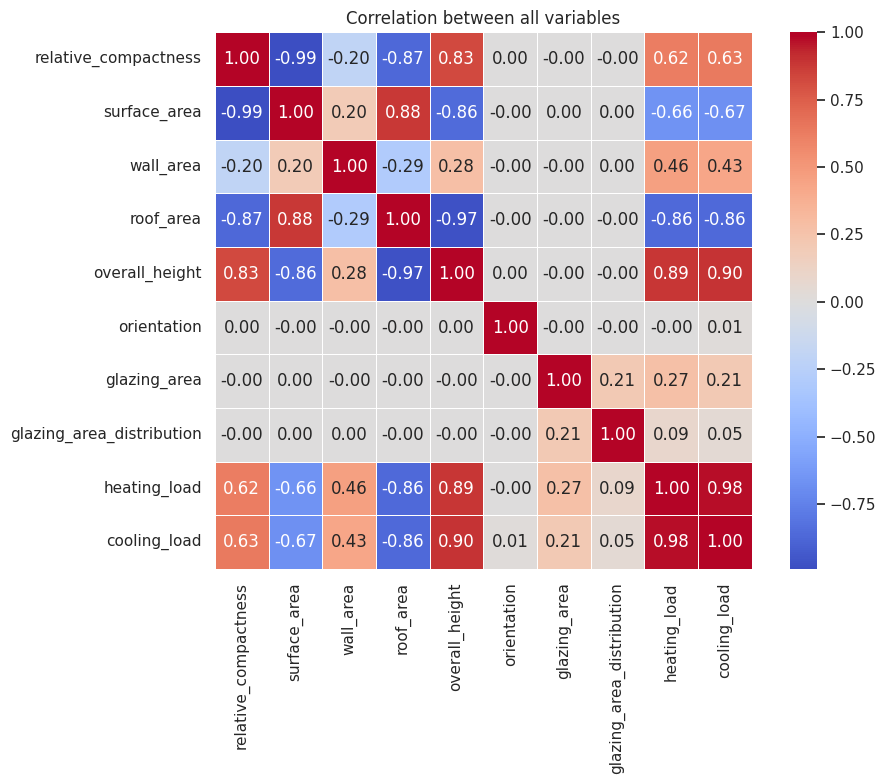

In [12]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlation between all variables")
plt.tight_layout()
plt.show()

In [13]:
# How each feature correlates with the two targets, sorted
target_corr = corr[["heating_load", "cooling_load"]].drop(
    ["heating_load", "cooling_load"])
print("Correlation of each feature with the targets:")
target_corr.sort_values("heating_load", ascending=False)

Correlation of each feature with the targets:


,heating_load,cooling_load
overall_height,0.889431,0.895785
relative_compactness,0.622272,0.634339
wall_area,0.455671,0.427117
glazing_area,0.269841,0.207505
glazing_area_distribution,0.087368,0.050525
orientation,-0.002587,0.014290
surface_area,-0.658120,-0.672999
roof_area,-0.861828,-0.862547


### 7.3 Feature vs. target scatter plots

The shape of each relationship tells us whether linear regression is a good fit.


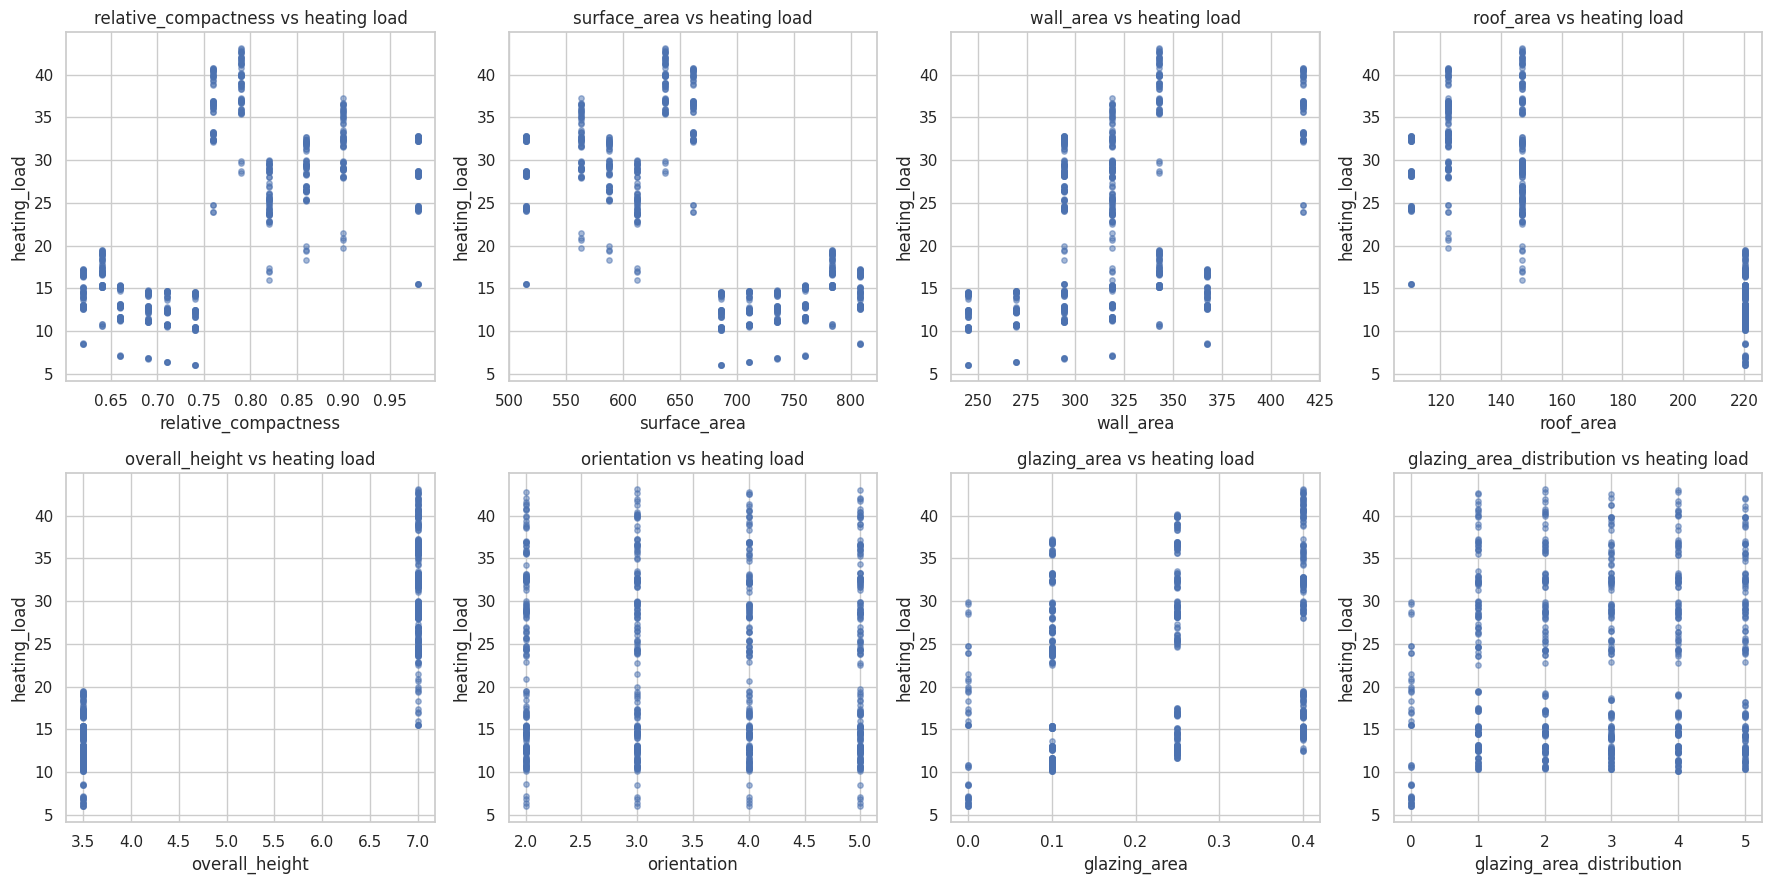

In [14]:
feature_cols = [
    "relative_compactness", "surface_area", "wall_area", "roof_area",
    "overall_height", "orientation", "glazing_area", "glazing_area_distribution",
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.flatten(), feature_cols):
    ax.scatter(df[col], df["heating_load"], alpha=0.5, s=15)
    ax.set_xlabel(col)
    ax.set_ylabel("heating_load")
    ax.set_title(f"{col} vs heating load")
plt.tight_layout()
plt.show()

## 8. Features, Targets, and Train/Test Split

`X` holds the 8 features. We keep the targets separate (`y_heating`, `y_cooling`) so each
gets its own model. We split 80% train / 20% test, using the **same split** for both targets
so results are comparable.


In [15]:
X = df[feature_cols]
y_heating = df["heating_load"]
y_cooling = df["cooling_load"]

# Split once; reuse the same row indices for the cooling target
X_train, X_test, yh_train, yh_test = train_test_split(
    X, y_heating, test_size=0.2, random_state=42)
yc_train = y_cooling.loc[yh_train.index]
yc_test = y_cooling.loc[yh_test.index]

print("Training rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])

Training rows: 614 | Test rows: 154


## 9. Scaling — Fit on Training Data Only

To avoid **data leakage**, we fit the scaler on the **training set only**, then apply it to
both train and test. The test set stays truly unseen.


In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaling done. Training mean ~0:", np.round(X_train_scaled.mean(), 3))

Scaling done. Training mean ~0: -0.0


## 10. Feature Engineering + PCA

The EDA showed strong multicollinearity among the shape features (compactness, surface area,
roof area, overall height). **PCA** combines correlated features into fewer independent
components. We check how many components keep most of the variance.


In [17]:
pca_full = PCA().fit(X_train_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
for i, (e, c) in enumerate(zip(explained, cumulative), start=1):
    print(f"PC{i}: explains {e*100:5.1f}%  |  cumulative {c*100:5.1f}%")

PC1: explains  46.3%  |  cumulative  46.3%
PC2: explains  15.6%  |  cumulative  62.0%
PC3: explains  15.0%  |  cumulative  76.9%
PC4: explains  12.4%  |  cumulative  89.4%
PC5: explains   9.9%  |  cumulative  99.3%
PC6: explains   0.7%  |  cumulative  99.9%
PC7: explains   0.1%  |  cumulative 100.0%
PC8: explains   0.0%  |  cumulative 100.0%


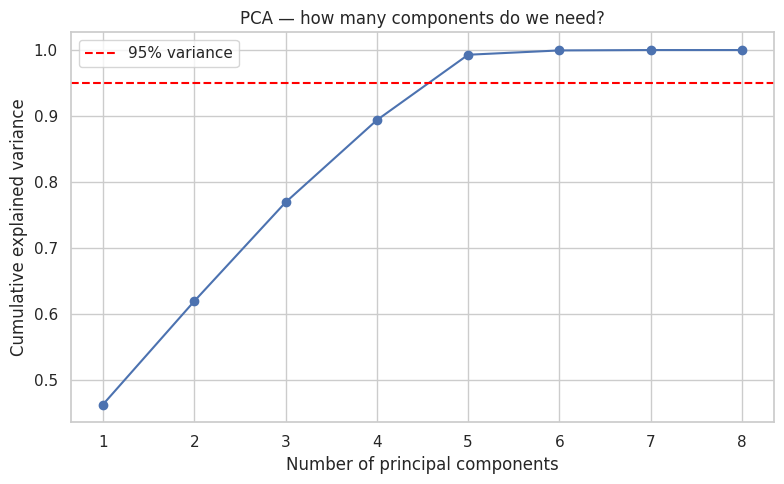

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
plt.axhline(y=0.95, color="red", linestyle="--", label="95% variance")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA — how many components do we need?")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# Keep enough components to explain 95% of the variance
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("Components kept:", pca.n_components_, "out of", X_train_scaled.shape[1])

Components kept: 5 out of 8


## 11. Regression Models

A helper function trains a model, predicts on the test set, and reports three metrics:
- **R²** — variance explained (closer to 1 is better)
- **MAE** — average error in kWh/m² (lower is better)
- **RMSE** — like MAE but punishes big errors more (lower is better)

We train four models, all built on linear-regression ideas (the course's scope):
Linear Regression (baseline), Ridge, Lasso, and Polynomial degree 2. We also compare a
Linear + PCA version.


In [20]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te, name=""):
    """Train a model, predict on the test set, and return its metrics."""
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    r2 = r2_score(y_te, preds)
    mae = mean_absolute_error(y_te, preds)
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    print(f"{name:<22} R2 = {r2:6.3f} | MAE = {mae:6.3f} | RMSE = {rmse:6.3f}")
    return {"model": name, "R2": r2, "MAE": mae, "RMSE": rmse}

### 11.1 Heating load

In [21]:
print("=== HEATING LOAD ===\n")
heating_results = []
heating_results.append(evaluate_model(
    LinearRegression(), X_train_scaled, yh_train, X_test_scaled, yh_test, "Linear Regression"))
heating_results.append(evaluate_model(
    Ridge(alpha=1.0), X_train_scaled, yh_train, X_test_scaled, yh_test, "Ridge"))
heating_results.append(evaluate_model(
    Lasso(alpha=0.1), X_train_scaled, yh_train, X_test_scaled, yh_test, "Lasso"))
heating_results.append(evaluate_model(
    make_pipeline(PolynomialFeatures(degree=2), LinearRegression()),
    X_train_scaled, yh_train, X_test_scaled, yh_test, "Polynomial (deg 2)"))
heating_results.append(evaluate_model(
    LinearRegression(), X_train_pca, yh_train, X_test_pca, yh_test, "Linear + PCA"))

=== HEATING LOAD ===

Linear Regression      R2 =  0.912 | MAE =  2.182 | RMSE =  3.025
Ridge                  R2 =  0.912 | MAE =  2.191 | RMSE =  3.035
Lasso                  R2 =  0.905 | MAE =  2.294 | RMSE =  3.153
Polynomial (deg 2)     R2 =  0.989 | MAE =  0.857 | RMSE =  1.064
Linear + PCA           R2 =  0.870 | MAE =  2.609 | RMSE =  3.682


### 11.2 Cooling load

In [22]:
print("=== COOLING LOAD ===\n")
cooling_results = []
cooling_results.append(evaluate_model(
    LinearRegression(), X_train_scaled, yc_train, X_test_scaled, yc_test, "Linear Regression"))
cooling_results.append(evaluate_model(
    Ridge(alpha=1.0), X_train_scaled, yc_train, X_test_scaled, yc_test, "Ridge"))
cooling_results.append(evaluate_model(
    Lasso(alpha=0.1), X_train_scaled, yc_train, X_test_scaled, yc_test, "Lasso"))
cooling_results.append(evaluate_model(
    make_pipeline(PolynomialFeatures(degree=2), LinearRegression()),
    X_train_scaled, yc_train, X_test_scaled, yc_test, "Polynomial (deg 2)"))
cooling_results.append(evaluate_model(
    LinearRegression(), X_train_pca, yc_train, X_test_pca, yc_test, "Linear + PCA"))

=== COOLING LOAD ===

Linear Regression      R2 =  0.893 | MAE =  2.195 | RMSE =  3.145
Ridge                  R2 =  0.893 | MAE =  2.196 | RMSE =  3.152
Lasso                  R2 =  0.884 | MAE =  2.305 | RMSE =  3.280
Polynomial (deg 2)     R2 =  0.956 | MAE =  1.607 | RMSE =  2.011
Linear + PCA           R2 =  0.833 | MAE =  2.749 | RMSE =  3.935


## 12. Compare the Results

Result tables and an R² bar chart


In [23]:
heating_df = pd.DataFrame(heating_results).set_index("model").round(3)
cooling_df = pd.DataFrame(cooling_results).set_index("model").round(3)
print("HEATING LOAD results:")
print(heating_df)
print("\nCOOLING LOAD results:")
print(cooling_df)

HEATING LOAD results:
                       R2    MAE   RMSE
model                                  
Linear Regression   0.912  2.182  3.025
Ridge               0.912  2.191  3.035
Lasso               0.905  2.294  3.153
Polynomial (deg 2)  0.989  0.857  1.064
Linear + PCA        0.870  2.609  3.682

COOLING LOAD results:
                       R2    MAE   RMSE
model                                  
Linear Regression   0.893  2.195  3.145
Ridge               0.893  2.196  3.152
Lasso               0.884  2.305  3.280
Polynomial (deg 2)  0.956  1.607  2.011
Linear + PCA        0.833  2.749  3.935


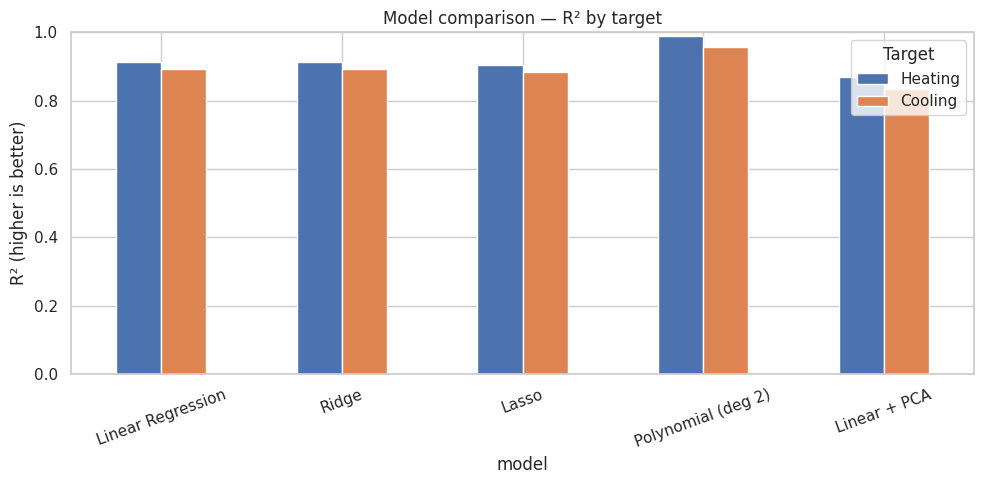

In [24]:
compare = pd.DataFrame({"Heating": heating_df["R2"], "Cooling": cooling_df["R2"]})
compare.plot(kind="bar", figsize=(10, 5))
plt.ylabel("R² (higher is better)")
plt.title("Model comparison — R² by target")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Target")
plt.tight_layout()
plt.show()

## 13. Cross-Validation

A single split can be lucky. **5-fold cross-validation** tests on five different parts and
averages the scores, which is more reliable. We run it on the Polynomial model.


In [25]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
X_scaled_all = StandardScaler().fit_transform(X)

for target_name, y_target in [("Heating", y_heating), ("Cooling", y_cooling)]:
    model = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
    scores = cross_val_score(model, X_scaled_all, y_target, cv=kf, scoring="r2")
    print(f"{target_name}: R2 per fold = {np.round(scores, 3)}")
    print(f"{target_name}: mean R2 = {scores.mean():.3f} (+/- {scores.std():.3f})\n")

Heating: R2 per fold = [0.989 0.989 0.99  0.99  0.989]
Heating: mean R2 = 0.990 (+/- 0.001)

Cooling: R2 per fold = [0.956 0.951 0.963 0.959 0.963]
Cooling: mean R2 = 0.958 (+/- 0.004)



## 14. Feature Importance

For a linear model, the size of each coefficient (on scaled data) shows how strongly that
feature pushes the energy load up or down.


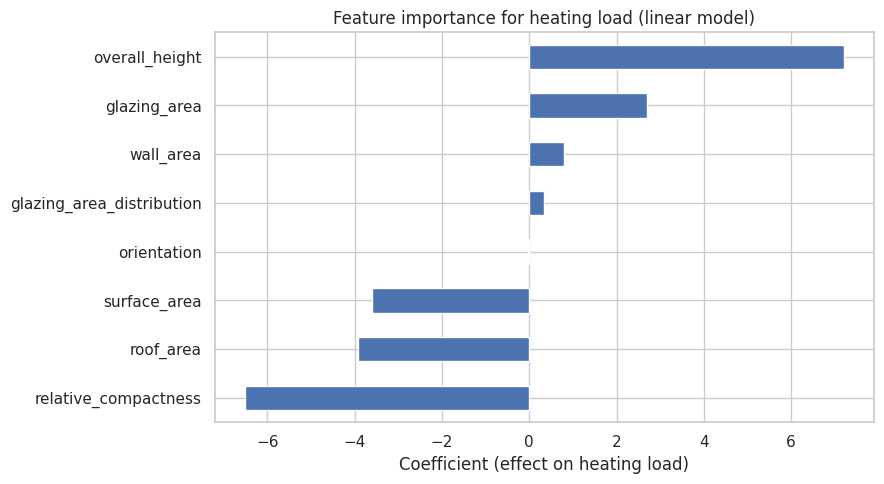

Coefficients (heating load):
relative_compactness        -6.518
roof_area                   -3.917
surface_area                -3.605
orientation                 -0.036
glazing_area_distribution    0.327
wall_area                    0.795
glazing_area                 2.700
overall_height               7.215
dtype: float32


In [26]:
lin_h = LinearRegression().fit(X_train_scaled, yh_train)
coeffs = pd.Series(lin_h.coef_, index=feature_cols).sort_values()

plt.figure(figsize=(9, 5))
coeffs.plot(kind="barh")
plt.xlabel("Coefficient (effect on heating load)")
plt.title("Feature importance for heating load (linear model)")
plt.tight_layout()
plt.show()

print("Coefficients (heating load):")
print(coeffs.round(3))

## 14b. Statistical Significance Test (Hypothesis Testing)

The correlation heatmap showed *how strong* each relationship is. A significance test checks
whether each relationship is **real or could be due to random chance**.

For every feature we compute its **Pearson correlation** with each target and the matching
**p-value**:
- **Null hypothesis (H0):** the feature has no real linear relationship with the load.
- If **p < 0.05**, we reject H0 — the relationship is **statistically significant**.


In [27]:
# Pearson correlation + p-value for every feature vs each target
from scipy.stats import pearsonr

rows = []
for col in feature_cols:
    r_h, p_h = pearsonr(df[col], df["heating_load"])
    r_c, p_c = pearsonr(df[col], df["cooling_load"])
    rows.append({
        "feature": col,
        "corr_heating": round(r_h, 3),
        "p_heating": f"{p_h:.1e}",
        "sig_heating": "Yes" if p_h < 0.05 else "No",
        "corr_cooling": round(r_c, 3),
        "p_cooling": f"{p_c:.1e}",
        "sig_cooling": "Yes" if p_c < 0.05 else "No",
    })

sig_df = pd.DataFrame(rows).set_index("feature")
print("Significance test (p < 0.05 means the relationship is statistically significant):\n")
print(sig_df)


Significance test (p < 0.05 means the relationship is statistically significant):

                           corr_heating p_heating sig_heating  corr_cooling  \
feature                                                                       
relative_compactness              0.622   1.6e-83         Yes         0.634   
surface_area                     -0.658   1.7e-96         Yes        -0.673   
wall_area                         0.456   1.2e-40         Yes         0.427   
roof_area                        -0.862  4.9e-228         Yes        -0.863   
overall_height                    0.889  1.1e-262         Yes         0.896   
orientation                      -0.003   9.4e-01          No         0.014   
glazing_area                      0.270   2.8e-14         Yes         0.208   
glazing_area_distribution         0.087   1.5e-02         Yes         0.051   

                          p_cooling sig_cooling  
feature                                          
relative_compactness      

## 15. Summary

- Loaded the UCI Energy Efficiency dataset directly (768 rows, 8 features, 2 targets)
- Confirmed **no missing values** and **no duplicates**; renamed columns; **reduced memory**
- Checked outliers (kept valid design values)
- Explored distributions, correlations, and feature–target relationships
- Split and scaled **without leakage**, used **PCA** for the overlapping shape features
- Trained four regression models for **each** target, compared **R²/MAE/RMSE**, and confirmed
  reliability with **cross-validation**
- Identified the most important features from the coefficients


